# 03. 사후 분석 — 왜 평가 점수가 교차검증보다 낮았나, CNN은 어디를 봤나

최종 평가 이후의 분석이다(PROTOCOL.md 8절). 여기서 본 결과로 모델, 설정, 보고한 점수를 바꾸지 않는다.
평가 예측은 `scripts/posthoc_predictions.py`가 저장한 파일을 읽는다.

질문
1. 라벨을 붙인 기준이 학습과 평가에서 달랐나?
2. 모델은 무엇과 무엇을 헷갈렸나?
3. Center를 왜 절반 가까이 놓쳤나?
4. CNN은 맵의 어디를 보고 판단했나? (Grad-CAM)

In [1]:
import sys, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn.metrics import f1_score
from src.data import load_train, CLASSES
from src.preprocess import stack_maps
from src.features import shape_features

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
CMAP = ListedColormap(["#ececec", "#9fc5a8", "#c0392b"])
train = load_train()
train["size"] = train.wafer_map.map(lambda m: f"{m.shape[0]}x{m.shape[1]}")
test = pd.read_pickle(ROOT / "data" / "processed" / "posthoc_test.pkl")
print("재현 확인 매크로 F1: M1 %.3f, M2 %.3f (최종 평가와 같아야 함)" % (
    f1_score(test.label, test.pred_m1, average="macro"), f1_score(test.label, test.pred_m2, average="macro")))

재현 확인 매크로 F1: M1 0.685, M2 0.714 (최종 평가와 같아야 함)


## 1. 라벨 기준이 달랐나

In [2]:
dup = test[test.train_label_same_map.notna()]
print(f"학습 데이터와 칸 값까지 똑같은 평가 맵: {len(dup):,}개, 라벨 일치율 {(dup.label == dup.train_label_same_map).mean():.1%}")
pd.crosstab(dup.train_label_same_map.rename("학습 라벨"), dup.label.rename("평가 라벨"))

학습 데이터와 칸 값까지 똑같은 평가 맵: 3,158개, 라벨 일치율 99.6%


평가 라벨,Center,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
학습 라벨,,,,,,,,
Center,5,0,0,1,0,0,0,1
Edge-Loc,0,29,0,0,0,0,0,1
Edge-Ring,0,2,6,0,0,0,0,0
Loc,0,0,0,18,0,0,0,0
Near-full,0,0,0,0,6,0,0,0
Random,0,0,0,0,0,14,0,0
Scratch,0,0,0,0,0,0,11,0
none,1,6,0,2,0,0,0,3055


**해석**: 똑같은 맵에 붙은 라벨이 학습과 평가에서 99.6% 같다. "평가 쪽은 완전히 다른 기준으로 라벨을 붙였다"고 보기는 어렵다.
다만 이 맵들은 대부분 `none`이라, 드문 패턴의 기준이 같았는지까지 보여주지는 않는다.

## 2. 무엇과 헷갈렸나

In [3]:
wrong = test[test.label != test.pred_m2]
pairs = wrong.groupby(["label", "pred_m2"]).size().sort_values(ascending=False).head(10).rename("개수").to_frame()
pairs.index.names = ["실제", "CNN 예측"]
pairs

개수
실제        CNN 예측        
none      Edge-Loc  1162
          Loc        723
Loc       none       472
Edge-Loc  none       458
none      Center     343
Center    none       256
none      Scratch    191
Loc       Edge-Loc   171
Edge-Ring Edge-Loc   170
          none       162

**해석**: 틀린 것의 대부분이 **패턴 ↔ none** 사이다.
- 가장 많은 실수는 `none`을 **Edge-Loc(1,162개)**, **Loc(723개)**, Center(343개)로 본 것이다. 평가 데이터는 93%가 `none`(11만 장)이라, 그중 1~2%만 잘못 판정해도 드문 패턴의 정밀도가 크게 떨어진다.
- 반대로 Loc(472개), Edge-Loc(458개), Center(256개)를 `none`으로 놓쳤다.
- 패턴끼리 헷갈린 것은 Loc ↔ Edge-Loc(171개), Edge-Ring → Edge-Loc(170개)처럼 위치나 범위만 다른 쌍이다.

## 3. Center를 왜 놓쳤나

In [4]:
groups = {
    "학습 Center": train[train.label == "Center"],
    "평가 Center (맞힘)": test[(test.label == "Center") & (test.pred_m2 == "Center")],
    "평가 Center (놓침)": test[(test.label == "Center") & (test.pred_m2 != "Center")],
    "평가 none → Center로 판정": test[(test.label == "none") & (test.pred_m2 == "Center")],
}
rows = []
for name, g in groups.items():
    F = shape_features(stack_maps(g.wafer_map))
    top = g["size"].value_counts()
    rows.append({"묶음": name, "개수": len(g), "불량 칩 비율": F.fail_rate.median(), "가운데 고리 불량 비율": F.ring_0.median(),
                 "가장 큰 덩어리 비율": F.largest_share.median(), "가장 흔한 크기": f"{top.index[0]} ({top.iloc[0] / len(g):.0%})"})
pd.DataFrame(rows).set_index("묶음").round(3)

,개수,불량 칩 비율,가운데 고리 불량 비율,가장 큰 덩어리 비율,가장 흔한 크기
묶음,,,,,
학습 Center,3462,0.266,0.782,0.323,25x27 (64%)
평가 Center (맞힘),431,0.120,0.435,0.173,34x34 (30%)
평가 Center (놓침),401,0.110,0.290,0.117,34x34 (28%)
평가 none → Center로 판정,343,0.088,0.250,0.130,29x26 (38%)


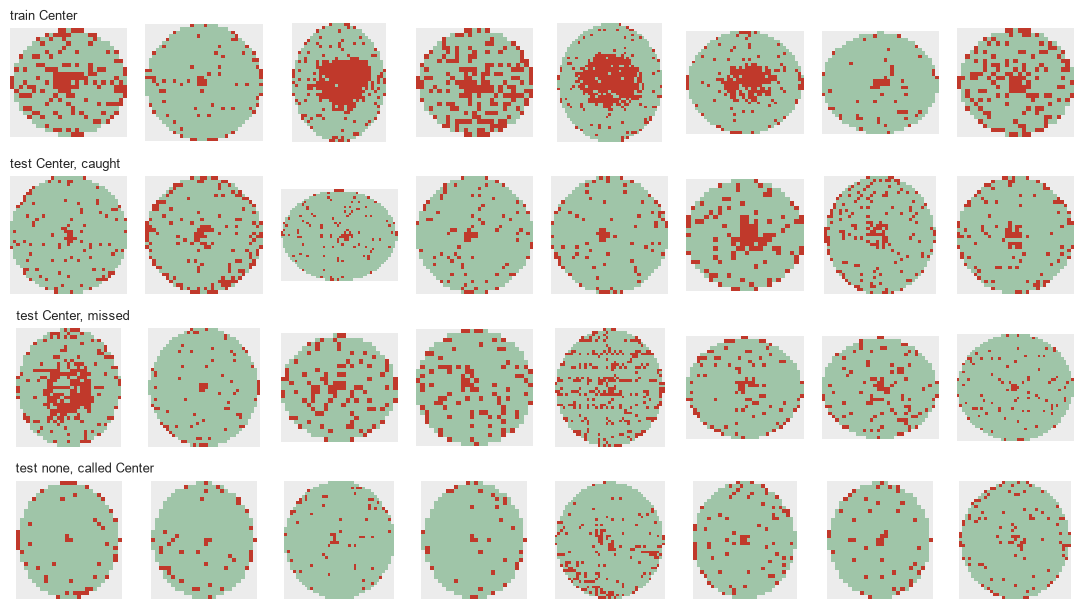

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(groups), 8, figsize=(11, 6.2))
for r, (name, g) in enumerate(groups.items()):
    for c, i in enumerate(rng.choice(len(g), 8, replace=False)):
        ax = axes[r, c]; ax.imshow(g.wafer_map.iloc[i], cmap=CMAP, vmin=0, vmax=2, interpolation="nearest"); ax.axis("off")
    axes[r, 0].set_title({0: "train Center", 1: "test Center, caught", 2: "test Center, missed", 3: "test none, called Center"}[r],
                         loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "11_center_shift.png", dpi=130)

**해석: 이 분석의 핵심**
- **학습 데이터의 Center는 64%가 한 제품(25x27)** 이고, 가운데 고리의 불량 비율이 0.78로 **진한 덩어리**다.
- **평가 데이터의 Center는 다른 제품들(34x34, 39x37 등)** 이고, 가운데 고리 불량 비율이 0.36으로 **훨씬 옅다**.
- 모델은 "Center = 가운데가 진하게 뭉친 것"으로 배웠고, 옅은 Center를 `none`으로 놓쳤다.
- 반대로 `none` 중 가운데가 조금 몰린 맵을 Center로 판정했는데, 이 맵들은 놓친 Center와 특징이 비슷하다(가운데 고리 0.25 vs 0.29). **옅은 Center와 none의 경계는 사람이 봐도 애매하다.**

즉 성능 하락의 큰 원인은 **학습 데이터의 패턴이 소수 제품에 치우쳐 있어서, 다른 제품의 같은 패턴을 일반화하지 못한 것**이다.

In [6]:
rows = []
for cls in [c for c in CLASSES if c != "none"]:
    tr, te = train[train.label == cls], test[test.label == cls]
    top = tr["size"].value_counts()
    rows.append({"패턴": cls, "학습 개수": len(tr), "학습에서 가장 흔한 크기 비중": top.iloc[0] / len(tr),
                 "평가 개수": len(te), "평가 웨이퍼 중 학습에 있던 크기 비율": te["size"].isin(set(tr["size"])).mean(),
                 "CNN 재현율": (te.pred_m2 == cls).mean()})
pd.DataFrame(rows).set_index("패턴").round(2)

,학습 개수,학습에서 가장 흔한 크기 비중,평가 개수,평가 웨이퍼 중 학습에 있던 크기 비율,CNN 재현율
패턴,,,,,
Center,3462,0.64,832,0.83,0.52
Donut,409,0.57,146,0.90,0.73
Edge-Loc,2417,0.11,2772,0.85,0.77
Edge-Ring,8554,0.22,1126,0.69,0.70
Loc,1620,0.11,1973,0.84,0.57
Near-full,54,0.33,95,0.20,0.95
Random,609,0.21,257,0.65,0.74
Scratch,500,0.11,693,0.57,0.64


**해석**
- **Center는 학습 데이터의 64%가 한 제품**에 몰려 있고, 평가 재현율이 0.52로 가장 낮다. 위의 분석과 같은 이야기다.
- 하지만 모든 패턴에 같은 경향이 있지는 않다. Loc은 학습 데이터가 여러 제품에 고르게 퍼져 있는데도(가장 흔한 크기 11%) 재현율이 0.57로 낮다.
  Loc은 "안쪽 한 부분에 몰림"이라 `none`의 흩어진 불량이나 Edge-Loc과 경계가 애매한 패턴이다.
- Near-full은 평가 웨이퍼의 80%가 학습에 없던 크기인데도 재현율 0.95다. 거의 전부 불량이라는 특징이 제품과 상관없이 뚜렷하기 때문이다.
- 정리하면, 성능 하락에는 **제품 치우침**(Center)과 **패턴 경계 자체의 애매함**(Loc, Edge-Loc과 none 사이)이 함께 작용한다.

## 4. Grad-CAM: CNN은 어디를 봤나

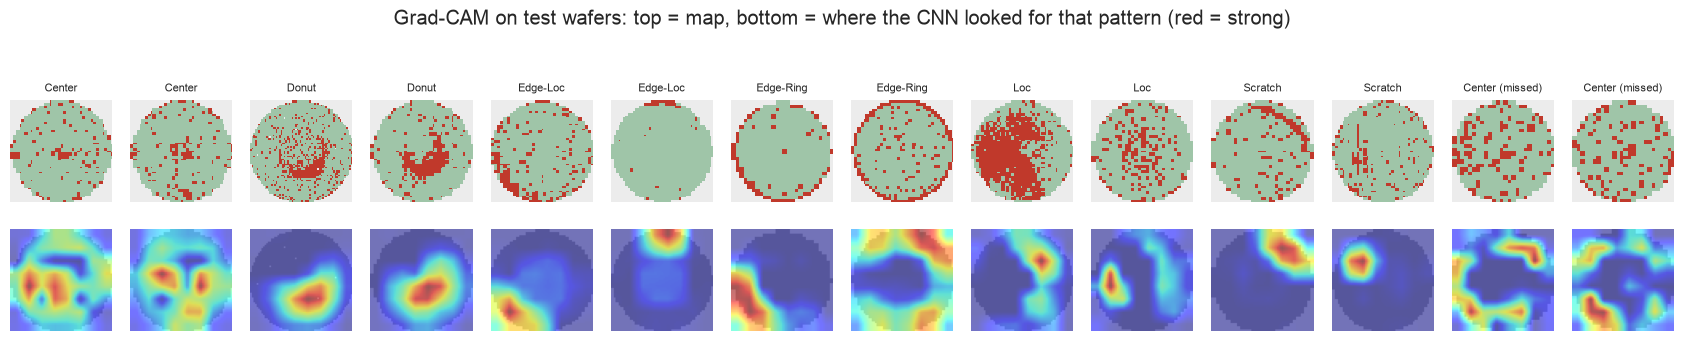

In [7]:
def gradcam(maps, target_names):
    x = stack_maps(maps)
    t = np.array([CLASSES.index(n) for n in target_names])
    tmp = ROOT / "data" / "processed"
    np.save(tmp / "cam_in.npy", x); np.save(tmp / "cam_t.npy", t)
    subprocess.run([sys.executable, str(ROOT / "scripts" / "gradcam.py"), str(tmp / "cam_in.npy"),
                    str(tmp / "cam_t.npy"), str(tmp / "cam_out.npy")], check=True)
    cams = np.load(tmp / "cam_out.npy")
    for f in ["cam_in.npy", "cam_t.npy", "cam_out.npy"]: (tmp / f).unlink()
    return x, cams

rng = np.random.default_rng(1)
picks = []
for cls in ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Scratch"]:
    ok = test[(test.label == cls) & (test.pred_m2 == cls)]
    picks += [(cls, ok.wafer_map.iloc[i]) for i in rng.choice(len(ok), 2, replace=False)]
missed = test[(test.label == "Center") & (test.pred_m2 == "none")]
picks += [("Center (missed)", missed.wafer_map.iloc[i]) for i in rng.choice(len(missed), 2, replace=False)]

x, cams = gradcam([m for _, m in picks], [n.split(" ")[0] for n, _ in picks])
fig, axes = plt.subplots(2, len(picks), figsize=(17, 3.6))
for i, (name, _) in enumerate(picks):
    die, fail = x[i, 0], x[i, 1]
    axes[0, i].imshow(die + fail, cmap=CMAP, vmin=0, vmax=2, interpolation="nearest")
    axes[1, i].imshow(die, cmap="Greys", alpha=0.25); axes[1, i].imshow(cams[i], cmap="jet", alpha=0.55, vmin=0, vmax=1)
    axes[0, i].set_title(name, fontsize=8)
    for a in axes[:, i]: a.axis("off")
fig.suptitle("Grad-CAM on test wafers: top = map, bottom = where the CNN looked for that pattern (red = strong)", y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR / "12_gradcam.png", dpi=130, bbox_inches="tight")

**해석**: 아래 줄에서 빨간 곳이 CNN이 그 패턴이라고 판단할 때 크게 기댄 위치다. 마지막 합성곱 지도가 8×8이라 위치는 대략적이다.
- **Donut**: 도넛 모양 불량 덩어리에 정확히 반응한다.
- **Edge-Loc**: 가장자리에 몰린 불량 부분(왼쪽 아래, 위쪽)에 반응한다.
- **Edge-Ring**: 가장자리 쪽에 반응한다. 고리 전체보다는 일부 구간에 몰려 있다.
- **Scratch**: 첫 번째는 휘어진 선을 따라 반응한다. 두 번째는 세로 선들보다 왼쪽 위 덩어리에 반응해, 선을 보고 판단했는지 분명하지 않다.
- **Center**: 맞힌 예에서도 가운데 한 곳이 아니라 여러 곳에 흩어져 반응한다. 평가 데이터의 Center가 옅어서 가운데 덩어리가 뚜렷하지 않기 때문으로 보인다.
- **놓친 Center**: 가운데가 아니라 가장자리 여기저기에 반응한다. 옅은 가운데 덩어리를 Center의 근거로 보지 못했다.

대부분의 패턴에서 CNN은 사람이 보는 곳과 비슷한 곳을 본다. Center처럼 근거가 약한 경우에는 반응이 흩어진다.

## 정리

| 질문 | 답 |
|---|---|
| 라벨 기준이 달랐나 | 똑같은 맵의 라벨은 99.6% 같다. 기준이 크게 달랐다고 보기 어렵다 (드문 패턴은 확인 범위가 좁음) |
| 무엇을 헷갈렸나 | 대부분 패턴 ↔ none. 평가 데이터 93%가 none이라 정밀도가 크게 떨어진다 |
| Center를 왜 놓쳤나 | 학습 Center가 한 제품(64%)의 진한 덩어리 위주였고, 평가 Center는 다른 제품의 옅은 덩어리였다 |
| CNN은 어디를 봤나 | Donut, Edge-Loc, Scratch(일부)는 사람이 보는 곳과 같은 곳. Center는 반응이 흩어짐 |

**교훈**
- 학습 데이터가 소수 제품에 치우쳐 있으면, 교차검증 점수가 높아도 다른 제품에서는 같은 패턴을 놓친다.
  실제 현장이라면 제품별로 고르게 라벨을 모으거나, **제품(크기) 단위로 나눈 교차검증**으로 이런 위험을 미리 측정해야 한다.
- 옅은 Center와 none, Loc과 흩어진 불량처럼 경계가 애매한 패턴은 라벨 기준을 더 명확히 정하는 것이 모델 개선만큼 중요하다.
- 이번 교차검증은 로트 단위로만 나눴다. 로트는 달라도 같은 제품이 학습과 검증에 함께 들어가서, 제품이 바뀌는 상황을 재지 못했다. 다음에는 제품 단위 교차검증도 함께 하겠다.